# Optimal Execution: How a Trader Sells a Large Block (Almgren-Chriss)

A client asks the desk to sell **1 million shares**, about a fifth of the stock's daily volume,
over the next five days. Sell fast and the price is pushed down by your own selling (**market
impact**); sell slowly and the price may fall anyway (**timing risk**). Almgren and Chriss (2000)
turned this trade-off into an optimisation problem:

$$\min_{x}\ \mathbb{E}[\text{shortfall}] + \lambda\,\mathrm{Var}[\text{shortfall}]$$

with linear permanent impact $\gamma$ (each share sold lowers the price for good), temporary impact
$\eta$ (selling fast costs more on the trade itself), and price volatility $\sigma$. The solution is
a closed-form trajectory: $x(t) = X\,\sinh(\kappa(T-t))/\sinh(\kappa T)$.

The parameters follow the numerical example of the original paper (a €50 stock with 30% annual vol).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("execution.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/29-optimal-execution")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from execution import Market, ac_trajectory, expected_cost_variance, vwap_trajectory, simulate_shortfall, efficient_frontier

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
m = Market()
m

Market(X=1000000, S0=50.0, sigma=0.95, T=5.0, N=50, eta=2.5e-06, gamma=2.5e-07, epsilon=0.0625)

## 1. Trading trajectories

- **TWAP** ($\lambda = 0$): sell the same amount in every interval, minimising expected cost.
- **Almgren-Chriss** with increasing risk aversion: sell more at the start to cut exposure.
- **VWAP**: follow the market's intraday volume curve, heavier at the open and the close.

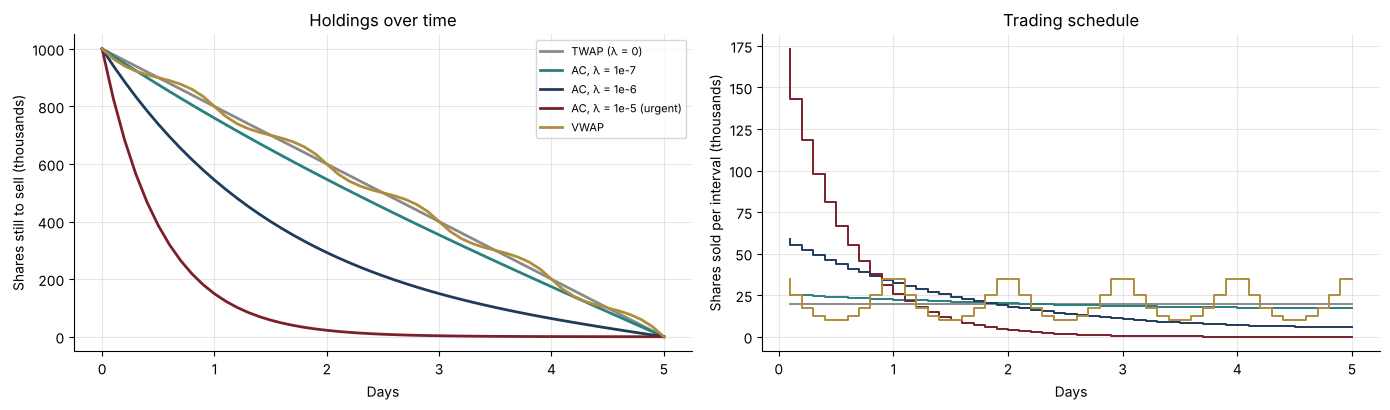

In [2]:
t = np.arange(m.N + 1) * m.tau
strategies = {"TWAP (λ = 0)": ac_trajectory(m, 0.0), "AC, λ = 1e-7": ac_trajectory(m, 1e-7), "AC, λ = 1e-6": ac_trajectory(m, 1e-6),
              "AC, λ = 1e-5 (urgent)": ac_trajectory(m, 1e-5), "VWAP": vwap_trajectory(m)}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for (name, x), c in zip(strategies.items(), [GREY, TEAL, NAVY, BORDEAUX, GOLD]):
    axes[0].plot(t, x / 1e3, color=c, lw=2, label=name)
    axes[1].step(t[1:], -np.diff(x) / 1e3, where="pre", color=c, lw=1.4, label=name)
axes[0].set(xlabel="Days", ylabel="Shares still to sell (thousands)", title="Holdings over time"); axes[0].legend(fontsize=8)
axes[1].set(xlabel="Days", ylabel="Shares sold per interval (thousands)", title="Trading schedule")
plt.tight_layout(); plt.savefig("images/trajectories.png", dpi=150); plt.show()

## 2. The efficient frontier of execution

Every value of $\lambda$ gives one trajectory, with an expected cost and a risk. The curve is the
execution equivalent of Markowitz's frontier: below it is impossible, above it is wasteful.

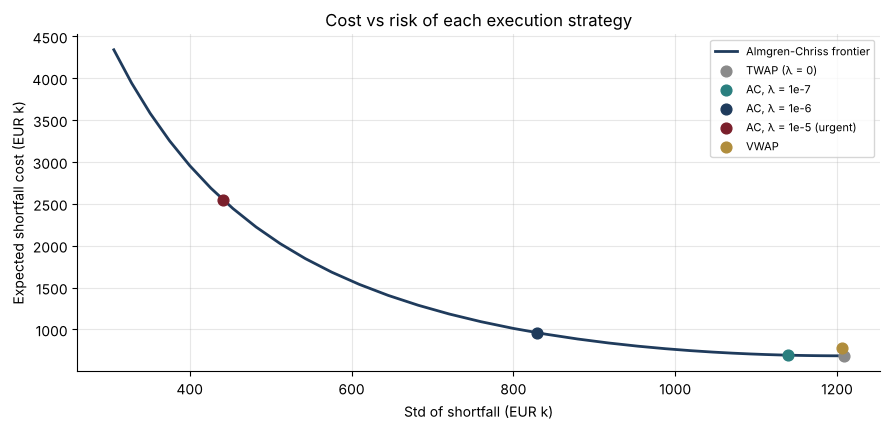

In [3]:
front = pd.DataFrame(efficient_frontier(m, np.logspace(-8, -4.5, 40)))
pts = {name: expected_cost_variance(m, x) for name, x in strategies.items()}
plt.figure(figsize=(9, 4.4))
plt.plot(front["std"] / 1e3, front["expected cost"] / 1e3, color=NAVY, lw=2, label="Almgren-Chriss frontier")
for (name, (E, V)), c in zip(pts.items(), [GREY, TEAL, NAVY, BORDEAUX, GOLD]):
    plt.scatter(np.sqrt(V) / 1e3, E / 1e3, color=c, s=60, zorder=4, label=name)
plt.xlabel("Std of shortfall (EUR k)"); plt.ylabel("Expected shortfall cost (EUR k)"); plt.legend(fontsize=8)
plt.title("Cost vs risk of each execution strategy")
plt.tight_layout(); plt.savefig("images/frontier.png", dpi=150); plt.show()

VWAP sits slightly off the frontier: following the volume curve concentrates trading at the
open and close, which costs more impact for almost the same risk as TWAP (in this model the
impact parameters do not depend on market volume, which is the real reason traders use VWAP).

## 3. Simulating 20,000 executions

The closed-form mean and variance are checked against a Monte Carlo of the price and impact
dynamics. The trader's real question is the **distribution** of the cost.

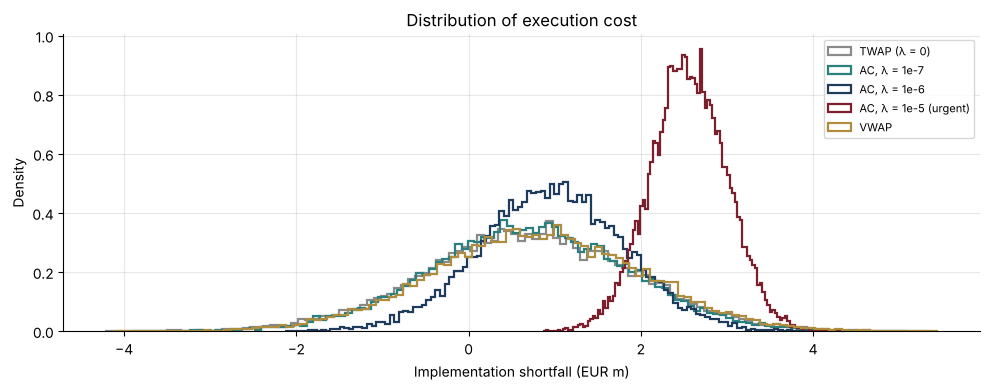

,Expected cost (formula),Mean cost (simulation),Std (formula),Std (simulation),95th percentile cost,Cost in bp of notional
Strategy,,,,,,
TWAP (λ = 0),685000.0,695750.0,1208032.0,1209204.0,2668241.0,139.0
"AC, λ = 1e-7",692710.0,703232.0,1139533.0,1140707.0,2568365.0,141.0
"AC, λ = 1e-6",961940.0,971054.0,828686.0,830097.0,2323910.0,194.0
"AC, λ = 1e-5 (urgent)",2545884.0,2551424.0,441579.0,442142.0,3278439.0,510.0
VWAP,783263.0,793871.0,1205987.0,1207305.0,2761836.0,159.0


In [4]:
rows, sims = [], {}
for name, x in strategies.items():
    sim = simulate_shortfall(m, x, n_paths=20_000, seed=1)
    E, V = pts[name]
    sims[name] = sim
    rows.append({"Strategy": name, "Expected cost (formula)": E, "Mean cost (simulation)": sim.mean(),
                 "Std (formula)": np.sqrt(V), "Std (simulation)": sim.std(), "95th percentile cost": np.quantile(sim, 0.95),
                 "Cost in bp of notional": sim.mean() / (m.X * m.S0) * 1e4})
fig, ax = plt.subplots(figsize=(10, 4))
for (name, sim), c in zip(sims.items(), [GREY, TEAL, NAVY, BORDEAUX, GOLD]):
    ax.hist(sim / 1e6, bins=120, histtype="step", lw=1.6, color=c, density=True, label=name)
ax.set(xlabel="Implementation shortfall (EUR m)", ylabel="Density", title="Distribution of execution cost"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/shortfall.png", dpi=150); plt.show()
pd.DataFrame(rows).set_index("Strategy").round(0)

**Reading the result.** TWAP has the lowest average cost (about 140 bp of the €50m order) but
the widest distribution. The urgent strategy cuts the risk by almost two thirds but pays nearly four
times more impact, so even its bad outcomes end up worse. The middle ground (λ = 1e-6) gives the
**lowest 95th-percentile cost**: this is the trajectory a trader would pick if the client cares about
avoiding a bad outcome rather than about the average.

## Conclusions
- The closed-form Almgren-Chriss cost and risk match the simulation (tested).
- Risk aversion front-loads the selling; λ = 0 gives back TWAP exactly.
- **Next steps:** non-linear (square-root) impact calibrated to market data, volume-dependent impact
  (where VWAP becomes optimal), limit orders and dark pools, and adaptive strategies that react to the price.